# Yambda 07 · BPR matrix factorization in PyTorch

Model code: `src/musicrec/models/bpr.py`. Same model family as iALS (user vector · item vector),
learned with a ranking loss and mini-batch gradient descent instead of closed-form least squares.

**Expectation, stated before running:** a well-tuned iALS usually beats BPR on this kind of data
(Rendle et al. 2022). The point of this stage: (1) a clean PyTorch training loop we reuse for
SASRec, (2) an honest comparison against the tuned iALS bar.

**First attempt (recorded, not re-run):** no time decay, lr = 0.001, one epoch = 7.3M triples
(~3 min/epoch on CPU). After 15 epochs (~45 min) val recall@10 = **0.0164** and still rising slowly:
under-trained, and below popularity (0.0235).

**This run:** 3-day half-life (the iALS winner), 5x higher learning rate, larger batches, and
2M sampled triples per "epoch" so we evaluate more often. Target: < 15 min in total.

Early stopping uses the validation targets. For the final test run we will *not* early-stop on
test; we retrain for the best epoch found here (`best_epoch_`).

In [1]:
import json, time
import pandas as pd
import matplotlib.pyplot as plt
import torch
from musicrec import config
from musicrec.preprocess import Split
from musicrec.evaluation import evaluate, paired_bootstrap
from musicrec.models.baselines import MostPopular
from musicrec.models.als import IALS
from musicrec.models.bpr import BPR

pd.set_option("display.float_format", "{:,.4f}".format)
print("torch", torch.__version__, "| device:", "cuda" if torch.cuda.is_available() else "cpu")
split = Split.load(config.YAMBDA_SPLIT_VAL_DIR)
OUT = config.PROJECT_ROOT / "reports" / "yambda"

torch 2.14.1+cpu | device: cpu


## Reference models: popularity and the tuned iALS (from `best_ials.json`, ~3 min)

In [2]:
runs = {}
def record(model):
    runs[model.name] = evaluate(model, split, return_per_user=True)
    print(f"{model.name:<60} recall@10={runs[model.name]['recall@10']:.4f}")

pop = MostPopular(by="listeners", recent_days=7).fit(split)
record(pop)
ials_params = json.loads((OUT / "best_ials.json").read_text())["params"]
t = time.time(); ials = IALS(**ials_params).fit(split); print(f"iALS fit {time.time() - t:.0f}s")
record(ials)

MostPopular(listeners, last 7d)                              recall@10=0.0235
iALS fit 199s
iALS(f=512, reg=50.0, alpha=30, half-life 3d)                recall@10=0.0346


## BPR with a 3-day half-life

In [3]:
bpr = BPR(dim=128, n_neg=4, lr=5e-3, reg=1e-5, batch_size=16384,
          samples_per_epoch=2_000_000, epochs=12, eval_every=2, patience=2, half_life_days=3)
print(bpr.name)
t = time.time(); bpr.fit(split); print(f"total {time.time() - t:.0f}s, best epoch {bpr.best_epoch_}")
record(bpr)

BPR(d=128, neg=4, lr=0.005, reg=1e-05, half-life 3d)
epoch  1  loss=0.3634  (32s)
epoch  2  loss=0.0896  (57s)  val recall@10=0.0287
epoch  3  loss=0.0453  (35s)
epoch  4  loss=0.0308  (42s)  val recall@10=0.0294
epoch  5  loss=0.0239  (25s)
epoch  6  loss=0.0198  (28s)  val recall@10=0.0281
epoch  7  loss=0.0172  (25s)
epoch  8  loss=0.0154  (32s)  val recall@10=0.0281
early stop: no improvement in 2 evaluations
total 359s, best epoch 4
BPR(d=128, neg=4, lr=0.005, reg=1e-05, half-life 3d)         recall@10=0.0294


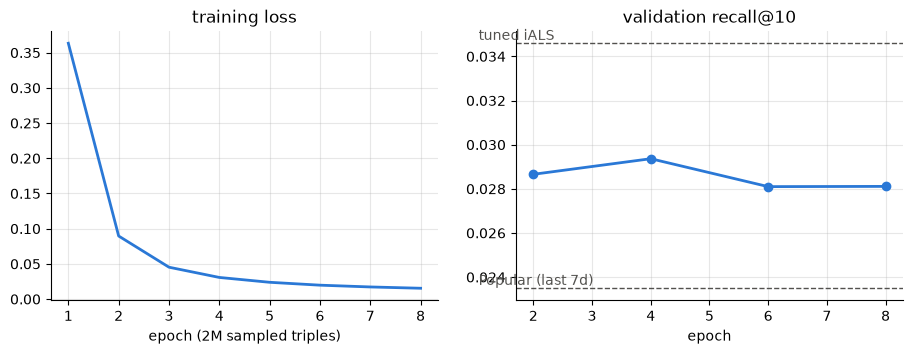

In [4]:
BLUE, GRAY = "#2a78d6", "#52514e"
h = pd.DataFrame(bpr.history_)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(h["epoch"], h["loss"], color=BLUE, lw=2)
v = h.dropna(subset=["val_recall@10"])
axes[1].plot(v["epoch"], v["val_recall@10"], color=BLUE, lw=2, marker="o")
for y, label in [(runs[ials.name]["recall@10"], "tuned iALS"), (runs[pop.name]["recall@10"], "Popular (last 7d)")]:
    axes[1].axhline(y, color=GRAY, lw=1, ls="--"); axes[1].text(h["epoch"].min(), y, f" {label}", va="bottom", color=GRAY)
axes[0].set(title="training loss", xlabel="epoch (2M sampled triples)")
axes[1].set(title="validation recall@10", xlabel="epoch")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False); ax.grid(alpha=0.3)
fig.savefig(config.YAMBDA_FIGURES_DIR / "y07_bpr_curves.png", dpi=150, bbox_inches="tight")

## Comparison

In [5]:
table = pd.DataFrame({n: {k: v for k, v in r.items() if k != "per_user"} for n, r in runs.items()}).T
table.loc["BPR(no decay, lr=0.001) [first attempt, 15 epochs]", "recall@10"] = 0.0164
table = table[["recall@10", "ndcg@10", "hit_rate@10", "recall@50", "coverage@10", "avg_pop@10"]].sort_values("recall@10", ascending=False)
table.to_csv(OUT / "results_val_bpr.csv")
table

,recall@10,ndcg@10,hit_rate@10,recall@50,coverage@10,avg_pop@10
"iALS(f=512, reg=50.0, alpha=30, half-life 3d)",0.0346,0.0322,0.1671,0.0686,0.0549,832.0774
"BPR(d=128, neg=4, lr=0.005, reg=1e-05, half-life 3d)",0.0294,0.0267,0.1488,0.0543,0.0352,974.9266
"MostPopular(listeners, last 7d)",0.0235,0.0224,0.1062,0.0428,0.0007,"1,819.4269"
"BPR(no decay, lr=0.001) [first attempt, 15 epochs]",0.0164,NaN,NaN,NaN,NaN,NaN


In [6]:
pd.DataFrame({
    "BPR vs popularity": paired_bootstrap(runs[pop.name]["per_user"], runs[bpr.name]["per_user"]),
    "BPR vs tuned iALS": paired_bootstrap(runs[ials.name]["per_user"], runs[bpr.name]["per_user"]),
}).T[["a", "b", "diff", "rel_diff", "ci_low", "ci_high", "p(b<=a)"]]

,a,b,diff,rel_diff,ci_low,ci_high,p(b<=a)
BPR vs popularity,0.0235,0.0294,0.0059,0.2498,0.0032,0.0084,0.0000
BPR vs tuned iALS,0.0346,0.0294,-0.0052,-0.1512,-0.0084,-0.0022,1.0000


In [7]:
(OUT / "best_bpr.json").write_text(json.dumps({"params": bpr.params(), "best_epoch": bpr.best_epoch_,
                                              "val_recall@10": runs[bpr.name]["recall@10"]}, indent=2))
print((OUT / "best_bpr.json").read_text())

{
  "params": {
    "dim": 128,
    "n_neg": 4,
    "lr": 0.005,
    "reg": 1e-05,
    "batch_size": 16384,
    "samples_per_epoch": 2000000,
    "weighting": "log",
    "half_life_days": 3
  },
  "best_epoch": 4,
  "val_recall@10": 0.029364520259201488
}


In [8]:
bpr_slow = BPR(dim=128, n_neg=4, lr=1e-3, reg=1e-5, batch_size=16384,
               samples_per_epoch=2_000_000, epochs=24, eval_every=3, patience=2, half_life_days=3)
print(bpr_slow.name)
t = time.time(); bpr_slow.fit(split); print(f"total {time.time() - t:.0f}s, best epoch {bpr_slow.best_epoch_}")
record(bpr_slow)
best = max([bpr, bpr_slow], key=lambda m: runs[m.name]["recall@10"])
display(pd.DataFrame({
    "best BPR vs popularity": paired_bootstrap(runs[pop.name]["per_user"], runs[best.name]["per_user"]),
    "best BPR vs tuned iALS": paired_bootstrap(runs[ials.name]["per_user"], runs[best.name]["per_user"]),
}).T[["a", "b", "diff", "rel_diff", "ci_low", "ci_high", "p(b<=a)"]])
(OUT / "best_bpr.json").write_text(json.dumps({"params": best.params(), "best_epoch": best.best_epoch_,
                                              "val_recall@10": runs[best.name]["recall@10"]}, indent=2))
print("saved best BPR:", best.name, "epoch", best.best_epoch_)

BPR(d=128, neg=4, lr=0.001, reg=1e-05, half-life 3d)
epoch  1  loss=0.6346  (19s)
epoch  2  loss=0.3083  (37s)
epoch  3  loss=0.1982  (45s)  val recall@10=0.0287
epoch  4  loss=0.1528  (44s)
epoch  5  loss=0.1196  (38s)
epoch  6  loss=0.0959  (47s)  val recall@10=0.0299
epoch  7  loss=0.0791  (47s)
epoch  8  loss=0.0670  (21s)
epoch  9  loss=0.0579  (34s)  val recall@10=0.0307
epoch 10  loss=0.0510  (40s)
epoch 11  loss=0.0454  (82s)
epoch 12  loss=0.0408  (76s)  val recall@10=0.0306
epoch 13  loss=0.0372  (93s)
epoch 14  loss=0.0339  (87s)
epoch 15  loss=0.0315  (14s)  val recall@10=0.0321
epoch 16  loss=0.0293  (16s)
epoch 17  loss=0.0273  (16s)
epoch 18  loss=0.0256  (17s)  val recall@10=0.0334
epoch 19  loss=0.0242  (15s)
epoch 20  loss=0.0228  (16s)
epoch 21  loss=0.0217  (16s)  val recall@10=0.0327
epoch 22  loss=0.0205  (17s)
epoch 23  loss=0.0195  (16s)
epoch 24  loss=0.0187  (16s)  val recall@10=0.0326
early stop: no improvement in 2 evaluations
total 1001s, best epoch 18
BPR(

,a,b,diff,rel_diff,ci_low,ci_high,p(b<=a)
best BPR vs popularity,0.0235,0.0334,0.0099,0.4207,0.0072,0.0126,0.0000
best BPR vs tuned iALS,0.0346,0.0334,-0.0012,-0.0352,-0.0043,0.0019,0.7565


saved best BPR: BPR(d=128, neg=4, lr=0.001, reg=1e-05, half-life 3d) epoch 18


In [9]:
for name, key in [(pop.name, "pop7d"), (ials.name, "ials"), (best.name, "bpr")]:
    runs[name]["per_user"].to_parquet(OUT / f"per_user_val_{key}.parquet", index=False)
import zipfile
root = config.PROJECT_ROOT
files = [*root.glob("src/**/*.py"), root / "pyproject.toml", root / "README.md",
         *(root / "data/processed/yambda").rglob("*.parquet"), *(root / "data/processed/yambda").rglob("*.json"),
         *(root / "reports/yambda").glob("*.json"), *(root / "reports/yambda").glob("per_user_val_*.parquet"),
         root / "data/raw/yambda/artist_item_mapping.parquet"]
with zipfile.ZipFile(root / "colab_bundle.zip", "w", zipfile.ZIP_STORED) as z:
    for f in files:
        z.write(f, f.relative_to(root))
print(round((root / "colab_bundle.zip").stat().st_size / 1e6), "MB")

441 MB
